# Telco Churn: Prioritising Customers for Retention

When contact capacity is limited, which customers should a retention team approach first? This notebook compares regularised logistic regression with a random forest. Both models rank customers by their churn scores.

Model selection uses cross-validated average precision. The test evaluation then measures how many historical churners appear among the highest-scoring 20% of customers. This contact budget is a scenario assumption, not an economically optimised threshold.

The project extends an earlier analysis of the same dataset. It evaluates the identification of observed churn; it does not establish performance over a future prediction horizon or the effect of contacting customers.

## 1. Loading and Cleaning the Data

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.inspection import permutation_importance

In [ ]:
RANDOM_STATE = 42
CONTACT_SHARE = 0.20 # Proportion of contacts to include in the analysis based on typical pareto distribution of churned customers
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
sns.set_theme(style="whitegrid")

raw = pd.read_csv(DATA_PATH, dtype={"customerID": "string"})
print(f"Raw data: {raw.shape[0]:,} customers, {raw.shape[1]} columns")
display(raw.head())

Raw data: 7,043 customers, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The file contains customer characteristics, contract and billing information, and the target variable `Churn`. The data path is relative to the notebook directory and can be changed above. Customer IDs are retained for matching predictions to customers but excluded from the model features.

In [2]:
df = raw.copy()
df.columns = df.columns.str.strip()
for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].str.strip()

n_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
if df["customerID"].isna().any() or df["customerID"].eq("").any() or df["customerID"].duplicated().any():
    raise ValueError("Customer IDs are missing or not unique.")
if not df["Churn"].isin(["Yes", "No"]).all():
    raise ValueError("Unexpected values in Churn.")

# Numeric conversion reveals missing values stored as blank strings.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_total = df["TotalCharges"].isna()
print(f"Exact duplicate rows: {n_duplicates}")
print(f"Missing total charges: {missing_total.sum()}")
display(df.loc[missing_total, ["tenure", "Churn"]].value_counts().rename("customers").to_frame())

df = df.loc[~missing_total].copy().reset_index(drop=True)
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
if df.isna().any().any():
    raise ValueError("Check remaining missing values before fitting the models.")
if df[["tenure", "MonthlyCharges", "TotalCharges"]].lt(0).any().any():
    raise ValueError("Negative tenure or billing values.")

print(f"Remaining customers: {len(df):,}")
display(df["Churn"].value_counts().rename("customers").to_frame().assign(
    share_pct=lambda table: table["customers"] / len(df) * 100
).round(2))

Exact duplicate rows: 0
Missing total charges: 11
Remaining customers: 7,032


,,customers
tenure,Churn,
0,No,11


,customers,share_pct
Churn,,
0,5163,73.42
1,1869,26.58


There are no exact duplicate rows. Eleven customers have missing total charges; all have zero months of tenure and no recorded churn. Excluding these records leaves 7,032 customers, including 1,869 churners (26.58%).

This exclusion specifically affects new customers. Its small size does not make it irrelevant: the results apply to the remaining sample with available billing information. `Churn = 1` indicates observed churn.

## 2. Exploring the Training Data

In [3]:
df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    stratify=df["Churn"],
    random_state=RANDOM_STATE,
)

df_train = df_train.copy()
df_test = df_test.copy()

eda = df_train.copy()

print(f"Training / exploration: {len(df_train):,} customers")
print(f"Held-out test:    {len(df_test):,} customers")
print(f"Training churn rate: {eda['Churn'].mean():.2%}")

display(
    eda[["tenure", "MonthlyCharges", "TotalCharges"]]
    .describe()
    .round(2)
)

if eda[["tenure", "MonthlyCharges", "TotalCharges"]].lt(0).any().any():
    raise ValueError("Negative tenure or charges found.")

Training / exploration: 5,625 customers
Held-out test:    1,407 customers
Training churn rate: 26.58%


,tenure,MonthlyCharges,TotalCharges
count,5625.00,5625.00,5625.00
mean,32.56,65.00,2301.84
std,24.54,30.11,2275.59
min,1.00,18.40,18.80
25%,9.00,35.80,413.00
50%,29.00,70.60,1410.25
75%,56.00,90.05,3801.70
max,72.00,118.65,8684.80


The stratified split produces 5,625 training customers and 1,407 test customers. Exploration uses only the training sample, which has a churn rate of 26.58%. Median tenure is 29 months and median monthly charges are 70.60.

Encoding and scaling are fitted later within cross-validation. A random customer split does not provide temporal validation. Since the same dataset was used in an earlier project, the test sample is also not a completely new external evaluation.

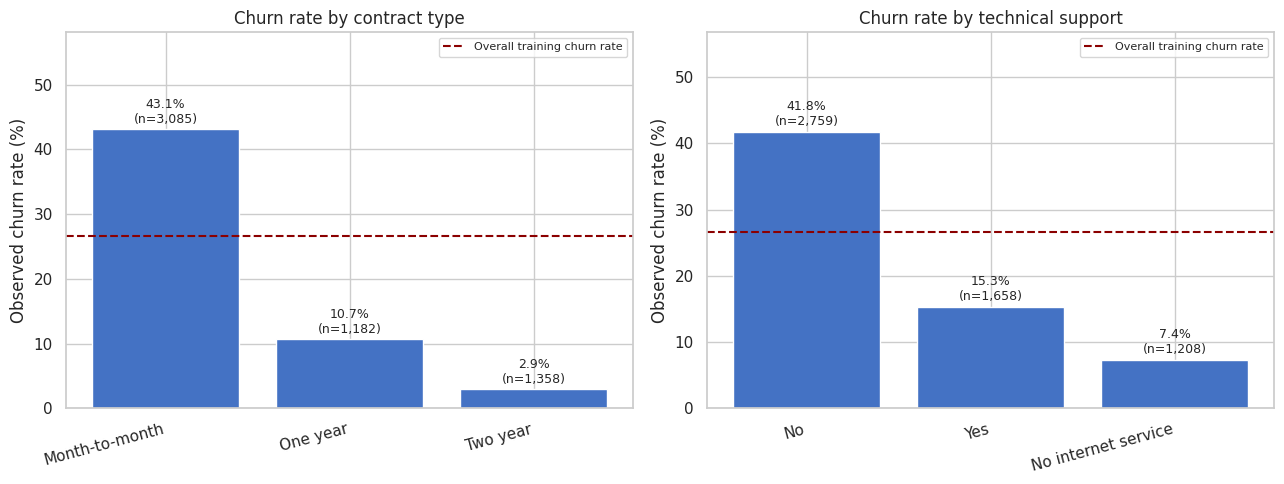

In [4]:
def group_churn_summary(data, column):
    """Calculate group sizes and observed churn rates."""
    summary = (
        data.groupby(column, observed=True, dropna=False)["Churn"]
        .agg(customers="size", churned="sum", churn_rate="mean")
    )
    summary["churn_rate_pct"] = summary["churn_rate"] * 100
    return summary

def plot_churn_rates(summary, ax, title, overall_rate):
    """Plot rates and group sizes, with the overall rate as a dashed line."""
    positions = np.arange(len(summary))

    ax.bar(positions, summary["churn_rate_pct"], color="#4472C4")
    ax.set_xticks(positions)
    ax.set_xticklabels(summary.index.astype(str), rotation=15, ha="right")
    ax.axhline(
        overall_rate * 100,
        color="darkred",
        linestyle="--",
        label="Overall training churn rate",
    )

    for position, (_, row) in zip(positions, summary.iterrows()):
        ax.text(
            position,
            row["churn_rate_pct"] + 1,
            f"{row['churn_rate_pct']:.1f}%\n(n={int(row['customers']):,})",
            ha="center",
            fontsize=9,
        )

    ax.set_ylim(
        0,
        min(110, max(overall_rate * 100,
                     summary["churn_rate_pct"].max()) + 15),
    )
    ax.set_ylabel("Observed churn rate (%)")
    ax.set_title(title)
    ax.legend(fontsize=8)

contract_summary = group_churn_summary(eda, "Contract").reindex(
    ["Month-to-month", "One year", "Two year"]
)

support_summary = group_churn_summary(eda, "TechSupport").reindex(
    ["No", "Yes", "No internet service"]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_churn_rates(contract_summary, axes[0], "Churn rate by contract type", eda["Churn"].mean())
plot_churn_rates(support_summary, axes[1], "Churn rate by technical support", eda["Churn"].mean())

plt.tight_layout()
plt.show()

Month-to-month customers have a higher observed churn rate than customers on one- or two-year contracts. Customers without technical support churn more frequently than those with support. Each bar includes the group size; the dashed line marks the training-sample average.

“No internet service” is a separate customer group. These differences do not establish that a longer contract or additional support would prevent churn.

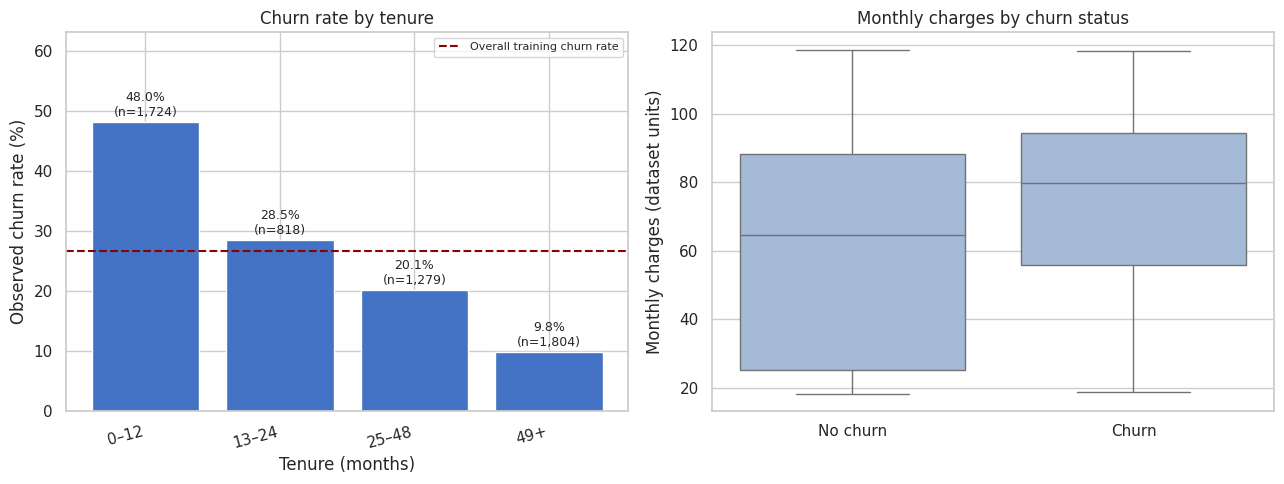

,customers,median,mean
churn_label,,,
Churn,1495,79.90,74.68
No churn,4130,64.68,61.50


In [5]:
tenure_labels = ["0–12", "13–24", "25–48", "49+"]

eda["tenure_group"] = pd.cut(
    eda["tenure"],
    bins=[-np.inf, 12, 24, 48, np.inf],
    labels=tenure_labels,
)

tenure_summary = group_churn_summary(
    eda, "tenure_group"
).reindex(tenure_labels)

eda["churn_label"] = eda["Churn"].map({
    0: "No churn",
    1: "Churn",
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_churn_rates(
    tenure_summary,
    axes[0],
    "Churn rate by tenure",
    eda["Churn"].mean(),
)
axes[0].set_xlabel("Tenure (months)")

sns.boxplot(
    data=eda,
    x="churn_label",
    y="MonthlyCharges",
    order=["No churn", "Churn"],
    color="#9BB9E0",
    ax=axes[1],
)
axes[1].set_title("Monthly charges by churn status")
axes[1].set_xlabel("")
axes[1].set_ylabel("Monthly charges (dataset units)")

plt.tight_layout()
plt.show()

display(
    eda.groupby("churn_label")["MonthlyCharges"]
    .agg(customers="size", median="median", mean="mean")
    .round(2)
)

Churn rates decline across the tenure groups shown. Monthly charges are also higher among churners: the median is 79.90, compared with 64.68 for customers who did not churn.

These are descriptive differences. Services, contract type and tenure may vary alongside charges, so the boxplot does not estimate a price effect. The plotting variables exist only in the EDA copy and are not used as model features.

Churn rate by internet service:


,customers,churned,churn_rate_pct
InternetService,,,
Fiber optic,2483,1038,41.80
DSL,1934,368,19.03
No,1208,89,7.37


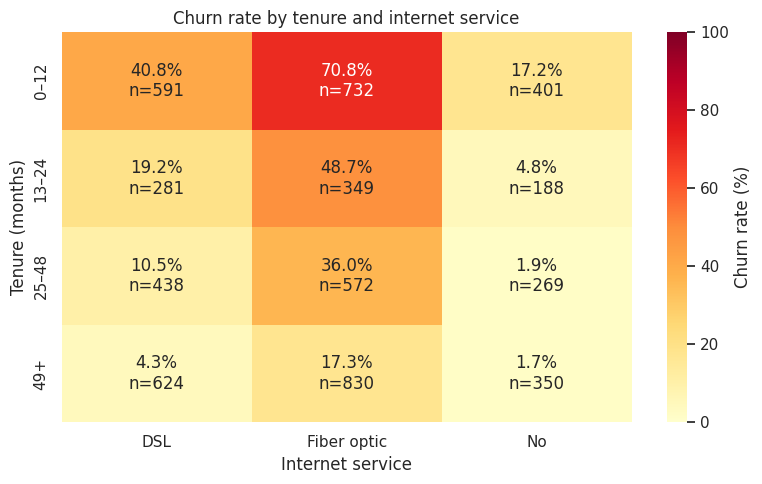

In [6]:
internet_summary = group_churn_summary(
    eda, "InternetService"
).sort_values("churn_rate_pct", ascending=False)

print("Churn rate by internet service:")
display(
    internet_summary[["customers", "churned", "churn_rate_pct"]].round(2)
)

combined_summary = (
    eda.groupby(
        ["tenure_group", "InternetService"],
        observed=True,
    )["Churn"]
    .agg(customers="size", churn_rate="mean")
    .reset_index()
)

rate_matrix = combined_summary.pivot(
    index="tenure_group",
    columns="InternetService",
    values="churn_rate",
).reindex(tenure_labels) * 100

count_matrix = combined_summary.pivot(
    index="tenure_group",
    columns="InternetService",
    values="customers",
).reindex(index=rate_matrix.index, columns=rate_matrix.columns)

annotations = pd.DataFrame(
    "",
    index=rate_matrix.index,
    columns=rate_matrix.columns,
)

for row in rate_matrix.index:
    for column in rate_matrix.columns:
        if pd.notna(rate_matrix.loc[row, column]):
            annotations.loc[row, column] = (
                f"{rate_matrix.loc[row, column]:.1f}%\n"
                f"n={int(count_matrix.loc[row, column]):,}"
            )

fig, ax = plt.subplots(figsize=(8, 5))

sns.heatmap(
    rate_matrix,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    mask=rate_matrix.isna(),
    cbar_kws={"label": "Churn rate (%)"},
    ax=ax,
)

ax.set_title("Churn rate by tenure and internet service")
ax.set_xlabel("Internet service")
ax.set_ylabel("Tenure (months)")

plt.tight_layout()
plt.show()

The training churn rate is 41.80% for fibre-optic customers, 19.03% for DSL customers and 7.37% for customers without internet service. The heatmap breaks down these rates by four tenure groups and includes the number of customers in each cell.

This provides more detail than the overall rates, but does not control for all other customer differences or establish a causal effect of internet service type.

In [7]:
billing_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
display(eda[billing_columns].corr().round(2))

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


The correlation matrix examines the relationship between tenure and billing. Total charges are associated with both the length of the customer relationship and monthly charges. All three features remain in the predictive comparison because they contain related but non-identical information.

Regularisation helps stabilise logistic regression with redundant predictors; it does not make their individual effects uniquely interpretable. The same dependencies also limit the interpretation of individual permutation importances later in the notebook.

## 3. Logistic Regression and Random Forest

In [8]:
feature_columns = [
    column for column in df_train.columns
    if column not in ["customerID", "Churn"]
]

X_train = df_train[feature_columns].copy()
X_test = df_test[feature_columns].copy()
y_train = df_train["Churn"].copy()
y_test = df_test["Churn"].copy()

numeric_columns = [
    "SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"
]
categorical_columns = [
    column for column in feature_columns
    if column not in numeric_columns
]

def make_preprocessor():
    return ColumnTransformer([
        ("numeric", StandardScaler(), numeric_columns),

        ("categorical", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
        ), categorical_columns),
    ])

logit_pipeline = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE,
    )),
])

forest_pipeline = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )),
])

Both models use the same input features, excluding the customer ID and target. Numeric features are standardised and categorical features are one-hot encoded. These transformations are fitted within each training fold, avoiding information transfer from the validation fold.

Scaling is unnecessary for random forests but is retained in the shared preprocessing approach. Model scores are used for ranking; their calibration as individual churn probabilities is not evaluated here.

In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

searches = {
    "Logit": GridSearchCV(
        logit_pipeline,
        param_grid={"model__C": [0.1, 1.0, 10.0]},
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score="raise",
    ),
    "Random Forest": GridSearchCV(
        forest_pipeline,
        param_grid={
            "model__max_depth": [5, 10],
            "model__min_samples_leaf": [5, 15],
        },
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score="raise",
    ),
}

cv_rows = []

for name, search in searches.items():
    search.fit(X_train, y_train)

    cv_rows.append({
        "model": name,
        "cv_average_precision": search.best_score_,
        "best_parameters": search.best_params_,
    })

cv_results = pd.DataFrame(cv_rows).set_index("model")

selected_model_name = cv_results["cv_average_precision"].idxmax()

display(cv_results)
print(f"Model selected by cross-validation: {selected_model_name}")

models = {
    name: search.best_estimator_
    for name, search in searches.items()
}

Model selected by cross-validation: Random Forest


,cv_average_precision,best_parameters
model,,
Logit,0.660171,{'model__C': 1.0}
Random Forest,0.666434,"{'model__max_depth': 10, 'model__min_samples_l..."


Five-fold cross-validation compares three regularisation strengths for logistic regression and four combinations of tree depth and minimum leaf size for the random forest.

The random forest has slightly higher mean average precision than logistic regression (approximately 0.666 versus 0.660). The higher-scoring model is selected before examining test performance. These best cross-validation scores are selection criteria, not independent performance estimates.

Average precision evaluates the ranking across multiple thresholds. The number of churners identified at a 20% contact budget is a separate operational measure; a higher average precision does not guarantee a better result at that particular budget.

## 4. Test Performance at a Fixed Contact Budget

In [ ]:
n_test = len(y_test)
n_contact = int(np.ceil(n_test * CONTACT_SHARE))
actual_churn = y_test.to_numpy()
total_churners = int(actual_churn.sum())
test_churn_rate = actual_churn.mean()

customer_ids = df_test["customerID"].astype(str).to_numpy()

test_rows = []
ranking_frames = []

for name, model in models.items():
    scores = model.predict_proba(X_test)[:, 1]

    ranking = pd.DataFrame({
        "customerID": customer_ids,
        "churn_score": scores,
        "actual_churn": actual_churn,
    }).sort_values(
        ["churn_score", "customerID"],
        ascending=[False, True],
    ).reset_index(drop=True)

    ranking["rank"] = np.arange(1, n_test + 1)
    ranking["selected_for_contact"] = ranking["rank"].le(n_contact)
    ranking["model"] = name

    identified_churners = int(
        ranking.loc[ranking["selected_for_contact"], "actual_churn"].sum()
    )

    precision = identified_churners / n_contact
    recall = identified_churners / total_churners

    test_rows.append({
        "model": name,
        "average_precision": average_precision_score(y_test, scores),
        "roc_auc": roc_auc_score(y_test, scores),
        "contacts": n_contact,
        "identified_churners": identified_churners,
        "precision_at_budget_pct": precision * 100,
        "recall_at_budget_pct": recall * 100,
        "lift_at_budget": precision / test_churn_rate,
    })

    ranking_frames.append(ranking)

test_results = pd.DataFrame(test_rows).set_index("model")
customer_rankings = pd.concat(ranking_frames, ignore_index=True)

print(f"Test customers: {n_test:,}")
print(f"Contact budget: {n_contact:,} customers ({n_contact / n_test:.1%})")
print(f"Observed churners in the test sample: {total_churners:,}")

display(test_results.round(3))

random_selection = pd.Series({
    "contacts": n_contact,
    "expected_identified_churners": n_contact * test_churn_rate,
    "expected_precision": test_churn_rate,
    "expected_recall": n_contact / n_test,
    "expected_lift": 1.0,
})

print("\nExpected performance of random selection:")
display(random_selection.round(3).to_frame("value"))

contact_list = (
    customer_rankings.loc[
        customer_rankings["model"].eq(selected_model_name)
        & customer_rankings["selected_for_contact"]
    ]
    .copy()
)

print(f"\nTop ten prioritised customers: {selected_model_name}")
display(
    contact_list[["rank", "customerID", "churn_score"]].head(10)
)

Test customers: 1,407
Contact budget: 282 customers (20.0%)
Observed churners in the test sample: 374

Expected performance of random selection:

Top ten prioritised customers: Random Forest


,average_precision,roc_auc,contacts,identified_churners,precision_at_budget_pct,recall_at_budget_pct,lift_at_budget
model,,,,,,,
Logit,0.623,0.836,282,187,66.312,50.000,2.495
Random Forest,0.644,0.840,282,182,64.539,48.663,2.428


,value
contacts,282.000
expected_identified_churners,74.959
expected_precision_pct,26.581
expected_recall_pct,20.043
expected_lift,1.000


,rank,customerID,churn_score
1407,1,1069-XAIEM,0.854955
1408,2,5542-TBBWB,0.852276
1409,3,9804-ICWBG,0.852276
1410,4,5178-LMXOP,0.851241
1411,5,1820-TQVEV,0.849578
1412,6,3716-BDVDB,0.845271
1413,7,8375-DKEBR,0.844659
1414,8,5539-TMZLF,0.843272
1415,9,5150-ITWWB,0.840205
1416,10,2609-IAICY,0.833989


Rounding up 20% of the 1,407 test customers gives a contact budget of 282. Precision measures the proportion of historical churners among selected customers. Recall measures the proportion of all 374 churners identified. Lift compares precision with the overall test churn rate.

The random forest identifies 182 churners (64.5% precision; 48.7% recall), while logistic regression identifies 187 (66.3%; 50.0%). Despite the forest’s higher average precision, logistic regression performs slightly better at this budget. This single split does not establish a reliable performance advantage. The model selected during cross-validation is not changed retrospectively based on test results.

The displayed list is a retrospective example from the test sample, not a deployment-ready list of current customers. Ties in model scores are resolved by customer ID, not by the observed churn label.

## 5. Which Features Does the Model Use?

,feature,mean_ap_decrease,std_ap_decrease
4,tenure,0.0857,0.0246
7,InternetService,0.0453,0.0078
18,TotalCharges,0.0426,0.0162
14,Contract,0.0324,0.0108
17,MonthlyCharges,0.0092,0.0073
15,PaperlessBilling,0.0083,0.0046
8,OnlineSecurity,0.0054,0.0057
11,TechSupport,0.0039,0.0059
16,PaymentMethod,0.0033,0.0047
6,MultipleLines,0.0023,0.0047


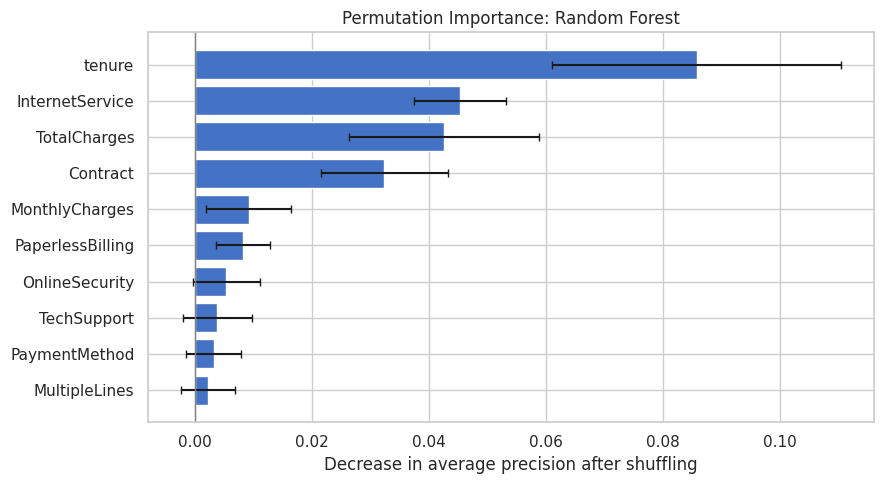

In [11]:
selected_model = models[selected_model_name]

importance_result = permutation_importance(
    selected_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "mean_ap_decrease": importance_result.importances_mean,
    "std_ap_decrease": importance_result.importances_std,
}).sort_values("mean_ap_decrease", ascending=False)

display(feature_importance.round(4))

top_features = (
    feature_importance.head(10)
    .sort_values("mean_ap_decrease")
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    top_features["feature"],
    top_features["mean_ap_decrease"],
    xerr=top_features["std_ap_decrease"],
    color="#4472C4",
    capsize=3,
)

ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("Decrease in average precision after shuffling")
ax.set_ylabel("")
ax.set_title(f"Permutation Importance: {selected_model_name}")

plt.tight_layout()
plt.show()

Tenure, internet service, total charges and contract type are among the most important features for the random forest. The chart shows the reduction in average precision when each input column is randomly shuffled. Categorical features are permuted as original columns rather than as separate dummy variables.

Error bars show standard deviations across ten permutations, not confidence intervals. Correlated features can substitute for one another, and permuting them separately can create unrealistic combinations of tenure and charges. These bars therefore represent neither independent contributions nor causal effects, and they do not indicate the direction of an association. This test-set analysis is descriptive and is not used for further feature selection.

## 6. Business Implications

,contacts,identified_churners,precision_at_budget_pct,recall_at_budget_pct,lift_at_budget,expected_churners_random,additional_historical_churners
model,,,,,,,
Logit,282,187,66.31,50.00,2.49,74.96,112.04
Random Forest,282,182,64.54,48.66,2.43,74.96,107.04


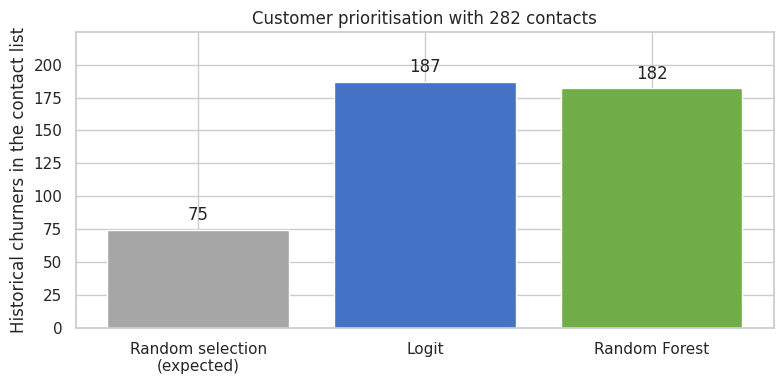

In [12]:
business_summary = test_results[[
    "contacts",
    "identified_churners",
    "precision_at_budget_pct",
    "recall_at_budget_pct",
    "lift_at_budget",
]].copy()

business_summary["expected_churners_random"] = (
    business_summary["contacts"] * y_test.mean()
)

business_summary["additional_historical_churners"] = (
    business_summary["identified_churners"]
    - business_summary["expected_churners_random"]
)

display(business_summary.round(2))

labels = ["Random selection\n(expected)"] + list(business_summary.index)
values = [n_contact * y_test.mean()] + (
    business_summary["identified_churners"].tolist()
)

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    labels,
    values,
    color=["#A6A6A6", "#4472C4", "#70AD47"],
)

ax.bar_label(bars, labels=[f"{value:.0f}" for value in values], padding=4)
ax.set_ylim(0, max(values) * 1.2)
ax.set_ylabel("Historical churners in the contact list")
ax.set_title(f"Customer prioritisation with {n_contact} contacts")

plt.tight_layout()
plt.show()

With 282 contacts, random selection would include approximately 75 historical churners on average. The random forest identifies 182 and logistic regression 187: approximately 107 and 112 additional churners, respectively. The demonstrated benefit is better prioritisation of limited contact capacity.

These additional matches are not prevented cancellations. Estimating financial value would require the incremental retention effect of an intervention, contact and offer costs, and retained contribution margin. A controlled campaign test would randomly assign prioritised customers to outreach or a control group, then compare incremental retention and net contribution margin.

## Conclusion

Both models concentrate historical churners substantially better than random selection. The random forest achieves higher average precision, while logistic regression identifies slightly more churners at the 20% contact budget. A clear practical benefit from the more complex model has not been demonstrated.

The project connects data cleaning, model selection and evaluation to a customer-prioritisation decision. Operational use would require features available before a defined churn horizon, temporal validation and a controlled campaign test. In particular, billing and contract information must be checked for availability before the churn event being predicted.

The analysis ends with this evaluation. Adding more models would not resolve the remaining questions about temporal generalisation or intervention effectiveness.